### 5b. The width factor $C$ — definition, derivation, and literature basis

Everything below rests on the size-distribution formalism of **Hansen & Travis (1974, §2.3)**.
For a droplet number distribution $n(r)$ with moments $M_k=\int_0^\infty r^k n(r)\,dr$ (so $M_0=N_c$),
the two radiatively meaningful summary parameters are the *area-weighted* mean radius and
relative variance,

$$r_{\rm eff}\;\equiv\;\frac{\int_{0}^{\infty} r\,\pi r^2 n(r)\,dr}{\int_{0}^{\infty} \pi r^2 n(r)\,dr}=\frac{M_3}{M_2}
\qquad\text{(H\&T Eq. 2.53)},\qquad
v_{\rm eff}\;\equiv\;\frac{\int_{0}^{\infty} (r-r_{\rm eff})^2\,\pi r^2 n(r)\,dr}{r_{\rm eff}^2\int_{0}^{\infty} \pi r^2 n(r)\,dr}
=\frac{M_4 M_2}{M_3^2}-1\qquad\text{(H\&T Eq. 2.54)},$$

— the second identity is what the cell above evaluates per CDP level. Area weighting is not a
convention but physics: droplet extinction is proportional to geometric cross-section, so these
are the moments radiation actually samples.

$$\text{VOLUME extinction coefficient: }\sigma_{\rm ext}=\int_{0}^{\infty} \pi r^2 Q_{\mathrm{ext}}(r) n(r) \, \mathrm{d}r \approx 2\pi M_2$$

given our large size parameters ($x=2\pi r/\lambda\sim50\text{–}200$). Consequently,

$$d\tau = \frac{\sigma_{\rm ext}}{\rho_{\rm air} g} dP = \frac{2\pi M_2}{\rho_{\rm air} g} dP = -2\pi M_2\ dz \ \text{by hydrostatic equation}$$

**Where $C$ enters.** The $\tau$ integrated for these profiles (§5 above; inherited from the
Buggee *readVocalsRex* MATLAB and kept for BP2025/26 comparability) uses the **monodisperse
second-moment shortcut** $M_2 \to M_0\,r_{\rm eff}^2$ since $M_0$ is approximately constant with height.

$$d\tau_{\rm built}=2\pi\,M_0\,r_{\rm eff}^2\,dz
\quad\text{vs}\quad
d\tau_{\rm true}=2\pi\,M_2\,dz
\;\;\Longrightarrow\;\;
\frac{d\tau_{\rm true}}{d\tau_{\rm built}}
=\frac{M_2}{M_0 r_{\rm eff}^2}\;\equiv\;C .$$

Following MJS1994,

$$C=\frac{M_2^3}{M_0 M_3^2}=\Big(\frac{r_v}{r_{\rm eff}}\Big)^{3}\;\le\;1,$$

where "volume-mean droplet radius" $r_v = \left( M_3 \middle/ M_0 \right)^{\frac{1}{3}}$; the bound is the log-convexity of moments — Lyapunov's
inequality, $M_2^3\le M_0M_3^2$ — with equality only for a monodisperse spectrum. Hence, the
shortcut overstates extinction. Assuming a gamma drop-size distribution, i.e. H&T's *standard distribution* (their Eq. 2.56),

$$n(r)\propto r^{(1-3b)/b}\,e^{-r/(ab)},$$

is the two-parameter gamma family constructed so that $a=r_{\rm eff}$ and $b=v_{\rm eff}$
exactly. Its moments follow from the $\Gamma$-integral, $\langle r^k\rangle=(ab)^k\,
\Gamma(\alpha+k)/\Gamma(\alpha)$ with $\alpha=(1-2b)/b$, so

$$\frac{\langle r^2\rangle}{a^2}=b^2\alpha(\alpha{+}1)=(1{-}2b)(1{-}b),\qquad
\frac{\langle r^3\rangle}{a^3}=(1{-}2b)(1{-}b)\underbrace{b(\alpha{+}2)}_{=1},\qquad
\frac{\langle r^4\rangle}{a^4}=(1{-}2b)(1{-}b)(1{+}b),$$

which verify $r_{\rm eff}=\langle r^3\rangle/\langle r^2\rangle=a$ and
$v_{\rm eff}=\langle r^4\rangle\langle r^2\rangle/\langle r^3\rangle^2-1=b$, and give

$$\boxed{\,C=(1-v_e)(1-2v_e)\,}$$

The $C\to0$ endpoint at $v_e=\tfrac12$ is the gamma family's
own validity boundary ($\alpha>0$ requires $b<\tfrac12$), which is why `vocals_io.width_factor_gamma`
clips there. **Shape sensitivity is second order:** a lognormal of equal $v_{\rm eff}$ gives
$C=(1+v_e)^{-3}$ — 0.864 vs the gamma 0.855 at $v_e=0.05$, and 0.751 vs 0.720 at $v_e=0.10$ —
and the binned CDP moments give $C(\tau)$ (actually $\tau$-dependent) *exactly*, with no shape assumption at all.

The correction $C$ needs to be applied to the LWP too since 

$$LWC := \rho_{\rm water} \int_0^\infty \frac{4}{3}\pi r^3 n(r) dr$$

and

$$
\begin{aligned}
LWP &= \int_0^\infty LWC(z) dz \\
&= \int_0^\infty \left( 4 \middle/ 3 \right) \pi \rho_{\rm water} M_3 dz \\
&= \int_0^{\tau_{\rm bot}} \frac{\left( 4 \middle/ 3 \right) \pi \rho_{\rm water} M_3}{2\pi M_2} d\tau \\
&= \frac{2}{3} \rho_{\rm water} \int_0^{\tau_{\rm bot; true}} r_e(\tau_{\rm true}) d\tau_{\rm true} \\
&= \frac{2}{3} \rho_{\rm water} C \int_0^{\tau_{\rm bot; built}} r_e(\tau_{\rm built}) d\tau_{\rm built}
\end{aligned}
$$


Applying the exact binned $C(\tau)$ closes the LWP identity to ~0.1 %, while the gamma closure through the measured
$v_{\rm eff}(\tau)$ leaves only ~1.3 % median residual (the "gamma-closure floor"), consistent
with gamma being an adequate — not perfect — model of marine-Sc spectra (Miles et al. 2000).

**References.**
* Hansen, J.E., Travis, L.D. Light scattering in planetary atmospheres. Space Sci Rev 16, 527–610 (1974). https://doi.org/10.1007/BF00168069
* Bohren, C. F., & Huffman, D. R. (1983). Absorption and scattering of light by small particles. John Wiley & Sons.
* Martin, G. M., D. W. Johnson, and A. Spice, 1994: The Measurement and Parameterization of Effective Radius of Droplets in Warm Stratocumulus Clouds. J. Atmos. Sci., 51, 1823–1842, https://doi.org/10.1175/1520-0469(1994)051<1823:TMAPOE>2.0.CO;2.
* Grosvenor, D. P., Sourdeval, O., Zuidema, P., Ackerman, A., Alexandrov, M. D., Bennartz, R., et al. (2018). Remote sensing of droplet number concentration in warm clouds: A review of the current state of knowledge and perspectives. Reviews of Geophysics, 56, 409–453. https://doi.org/10.1029/2017RG000593

### 5c. Can a single $v_e$ zero the LWP bias?

Per profile, **yes — exactly one**. A constant $v_e$ enters the LWP bookkeeping only through the
constant width factor $C=(1-v_e)(1-2v_e)$, so $LWP_{\rm native}\cdot C(v_e^*)=\int LWC\,dz$ inverts
in closed form (`vocals_io.zero_bias_veff`; $C$ derived in §5b above).
Across the ensemble that **zero-bias constant is itself a distribution** — median **0.037**
(MAD 0.018, p5–p95 0.020–0.085) — tracking each profile's true column width (corr 0.89 with the
column-mean in-situ $v_e$, and nearly independent of $\tau_{\rm bot}$), and sitting nowhere near
the optics assumption 0.10. Globally, switching to the *mean* aggregation (to match §16 Fig 5): the mean-bias-zeroing constant shifts up from the old median-zeroing 0.037 (exact value pending the VOCALS re-run), while
$v_e\approx0.046$ minimizes the RMS (7.5 %) — but the spread of $v_e^*$ is irreducible by **any**
single constant (RMS ≥ 7.5 %, vs 18.3 % at $v_e{=}0.10$ and 17.2 % uncorrected). Removing the
residual requires the per-profile route (the `ve_retrieval` branch pipeline — cloudbow-top $v_e$ +
climatological completion — reaches 3.0 % med|b| / 5.1 % RMS).

zero-bias v_e*: median 0.037  MAD 0.018  [p5 0.020, p95 0.085]  range [0.014,0.124]  n=125
no correction          v=0.000: median +12.21%  med|b| 12.21%  RMS 17.25%
optics v_e=0.10        v=0.100: median -19.21%  med|b| 19.21%  RMS 18.33%
BP26 column-mean 0.055 v=0.055: median  -5.63%  med|b|  7.11%  RMS  7.98%
zero-MEDIAN-bias       v=0.037: median  +0.00%  med|b|  4.03%  RMS  8.06%
min-RMS                v=0.046: median  -2.96%  med|b|  5.45%  RMS  7.48%
corr(v*, column-mean v_eff) = 0.89; corr(v*, tau_bot) = -0.15


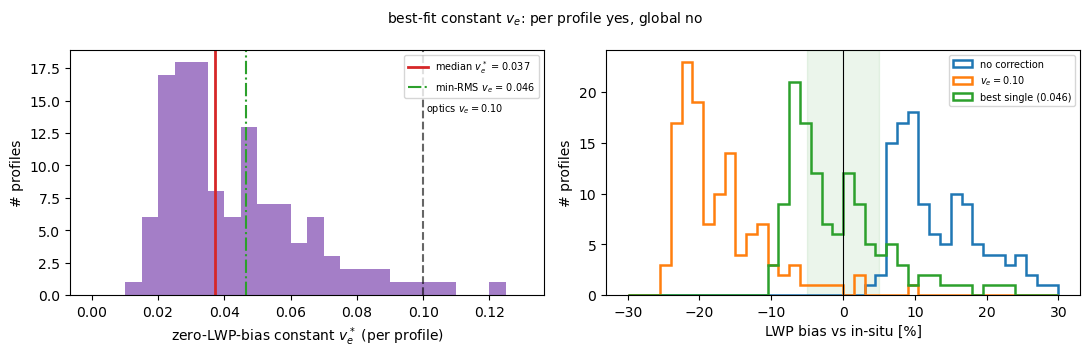

In [9]:
# The zero-LWP-bias constant v_e — the best-fit single v_e per profile (vocals_io.zero_bias_veff):
# a constant v_e is a constant width factor C=(1-v)(1-2v), so LWP_native*C(v*) = int LWC dz inverts exactly.
kept = [p for p in profiles if 0.3 <= p.tau_bot <= 60]          # same physical filter as above
lwp_t = np.array([vio.lwp_true_z(p) for p in kept])
lwp_n = np.array([vio.lwp_native(p) for p in kept])
ratio = lwp_t / lwp_n
vstar = np.asarray(vio.veff_from_width_factor(ratio))           # zero-bias v_e*, per profile
med_v = np.median(vstar); mad_v = median_abs_deviation(vstar, scale='normal')
print(f'zero-bias v_e*: median {med_v:.3f}  MAD {mad_v:.3f}  [p5 {np.percentile(vstar,5):.3f}, '
      f'p95 {np.percentile(vstar,95):.3f}]  range [{vstar.min():.3f},{vstar.max():.3f}]  n={vstar.size}')
grid = np.arange(0.0, 0.2001, 0.0005)
rms = lambda b: np.sqrt(np.mean(b ** 2))
bias_of = lambda v: 100.0 * (np.asarray(vio.width_factor_gamma(v)) / ratio - 1.0)
v_min_rms = float(grid[np.argmin([rms(bias_of(v)) for v in grid])])
v_zero_mean = float(grid[np.argmin([abs(np.mean(bias_of(v))) for v in grid])])  # mean-bias analogue of med_v (matches Fig 5)
for name, v in [('no correction', 0.0), ('optics v_e=0.10', 0.10), ('BP26 column-mean 0.055', 0.055),
                ('zero-MEAN-bias', v_zero_mean), ('min-RMS', v_min_rms)]:
    b = bias_of(v)
    print(f'{name:22s} v={v:5.3f}: mean {np.mean(b):+6.2f}%  mean|b| {np.mean(np.abs(b)):5.2f}%  '
          f'RMS {rms(b):5.2f}%')
print(f'corr(v*, column-mean v_eff) = {np.corrcoef(vstar, [p.v_eff.mean() for p in kept])[0,1]:.2f}; '
      f'corr(v*, tau_bot) = {np.corrcoef(vstar, [p.tau_bot for p in kept])[0,1]:.2f}')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(vstar, bins=np.linspace(0, 0.13, 27), color='C4', alpha=0.85)
ax[0].axvline(0.10, ls='--', color='k', alpha=0.6)
ax[0].text(0.101, ax[0].get_ylim()[1] * 0.75, 'optics $v_e{=}0.10$', fontsize=7)
ax[0].axvline(v_zero_mean, color='C3', lw=2, label=f'zero-mean-bias $v_e$ = {v_zero_mean:.3f}')
ax[0].axvline(v_min_rms, color='C2', ls='-.', label=f'min-RMS $v_e$ = {v_min_rms:.3f}')
ax[0].set_xlabel(r'zero-LWP-bias constant $v_e^*$ (per profile)'); ax[0].set_ylabel('# profiles')
ax[0].legend(fontsize=7)
bins = np.linspace(-30, 30, 41)
for v, lab, c in [(0.0, 'no correction', 'C0'), (0.10, r'$v_e{=}0.10$', 'C1'),
                  (v_min_rms, f'best single ({v_min_rms:.3f})', 'C2')]:
    ax[1].hist(bias_of(v), bins=bins, histtype='step', lw=1.8, color=c, label=lab)
ax[1].axvspan(-5, 5, color='green', alpha=0.08); ax[1].axvline(0, color='k', lw=0.8)
ax[1].set_xlabel('LWP bias vs in-situ [%]'); ax[1].set_ylabel('# profiles'); ax[1].legend(fontsize=7)
fig.suptitle('best-fit constant $v_e$: per profile yes, global no',
             fontsize=10)
plt.tight_layout()